# 02 — Baseline: what each component does, case by case

A handful of requests at a time, with the cluster idle between them, and a
reading of **every component** for each case. Nothing here is about limits.
It is about what each piece does when it has room, so that a number measured
under load in 03 can be explained rather than only reported.

Two things decide what every component does, so those are the only two things
the cases vary:

- **how long the prompt is** — a 500-token question and a 14,000-token
  research turn are different workloads, not the same one scaled
- **whether its prefix is already resident** — a cached prompt never touches
  the KV hop, so measuring only repeats would make disaggregation look idle

Every number is a **delta across one case**, scraped from the engines before
and after. The previous version of this notebook read cumulative counters and
reported an average over every request the pods had ever served — true, and
attributable to nothing we chose.

Run `make cluster` and `make ssh` first.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1] if Path.cwd().name == '02-baseline' else Path.cwd()
sys.path.insert(0, str(ROOT / 'benchmarking'))
%load_ext autoreload
%autoreload 2

from bench import CASES, run_case, settle, SHED_ABOVE
from prom import Prom
from utils import Report
from slos import SLOS, TTFT_BUDGET_S, SPEECH_TOKENS_PER_S, ITL_STUTTER_S, budget_rows

prom, report = Prom(), Report('02-baseline')
N = 5          # requests per case; enough to average, small enough to stay idle


## Objective


In [2]:
report.table(['stage of the speech path', 'budget', ''], budget_rows(),
             note='these are serial on the way to first audio, so the engine gets '
                  'a slice of the 1.5s a listener tolerates, not all of it.')

report.objective(
    'With room to spare, what does each component actually do — and does that '
    'change with prompt length and cache state?',
    slos=['ttft_p95', 'itl_p95', 'preemptions'],
    falsified_by='the prefix cache hitting on text the engine has never seen, '
                 'decode recomputing a prompt prefill already built, or first '
                 f'token missing {TTFT_BUDGET_S:g}s on an idle cluster — which '
                 'would mean load is not what breaks the budget.')


  stage of the speech path   budget                             
  -------------------------  -------  --------------------------
  ASR endpoint and finalize  300 ms                             
  LLM TTFT                   800 ms   what the engine is held to
  TTS first chunk            200 ms                             
  network and orchestration  200 ms                             
  first audio                1500 ms  what a listener tolerates 
  -- these are serial on the way to first audio, so the engine gets a slice of the 1.5s a listener tolerates, not all of it.

Objective
  With room to spare, what does each component actually do — and does that change with prompt length and cache state?
  SLO under test           target
  -----------------------  ------
  TTFT p95                 0.8s  
  inter-token latency p95  0.08s 
  preemptions              0     
  Falsified by: the prefix cache hitting on text the engine has never seen, decode recomputing a prompt prefill already b

Report(title='02-baseline', subtitle='', blocks=[_Block(kind='table', payload=(['stage of the speech path', 'budget', ''], [['ASR endpoint and finalize', '300 ms', ''], ['LLM TTFT', '800 ms', 'what the engine is held to'], ['TTS first chunk', '200 ms', ''], ['network and orchestration', '200 ms', ''], ['first audio', '1500 ms', 'what a listener tolerates']]), note='these are serial on the way to first audio, so the engine gets a slice of the 1.5s a listener tolerates, not all of it.'), _Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='With room to spare, what does each component actually do — and does that change with prompt length and cache state?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '0.8s'], ['inter-token latency p95', '0.08s'], ['preemptions', '0']]), note=''), _Block(kind='text', payload='Falsified by: the prefix cache hitting on text the engine has never seen, decode recomputing a prompt prefill alre

## 1. The cases

Each one states what it is for before it runs. A baseline nobody can falsify
is a description, not a measurement.


In [3]:
report.heading('1. The cases')
report.table(['case', 'prompt', 'prefix', 'what it isolates'],
             [[c.label, f'{c.prompt_tokens:,} tok', c.prefix, c.why]
              for c in CASES.values()],
             note='prefix: novel = never seen, repeat = sent once to warm it, '
                  'partial = half shared with a warmed prompt.')



1. The cases
  case                   prompt      prefix   what it isolates                                                                                                                                                                              
  ---------------------  ----------  -------  ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
  short, never seen      500 tok     novel    The cheapest thing the cluster can be asked to do, and the only case where the engine is not reading a long prompt.                                                                           
  short, already cached  500 tok     repeat   Isolates the prefix cache from prompt length: same text, second time.                                                                                                                         
  long, never seen       14,000 tok  n

Report(title='02-baseline', subtitle='', blocks=[_Block(kind='table', payload=(['stage of the speech path', 'budget', ''], [['ASR endpoint and finalize', '300 ms', ''], ['LLM TTFT', '800 ms', 'what the engine is held to'], ['TTS first chunk', '200 ms', ''], ['network and orchestration', '200 ms', ''], ['first audio', '1500 ms', 'what a listener tolerates']]), note='these are serial on the way to first audio, so the engine gets a slice of the 1.5s a listener tolerates, not all of it.'), _Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='With room to spare, what does each component actually do — and does that change with prompt length and cache state?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '0.8s'], ['inter-token latency p95', '0.08s'], ['preemptions', '0']]), note=''), _Block(kind='text', payload='Falsified by: the prefix cache hitting on text the engine has never seen, decode recomputing a prompt prefill alre

## 2. Running them

The cluster is drained between cases. Without that, one case's leftovers set
the next case's starting conditions — and on this cluster a case can be
refused outright because the previous one left KV above the router's shed
line.


In [4]:
report.heading('2. Running them')

state = settle()
report.table(['pool', 'KV', 'waiting', 'running'],
             [[p, f"{state[f'{p}_kv']:.1%}", f"{state[f'{p}_waiting']:.0f}",
               f"{state[f'{p}_running']:.0f}"] for p in ('prefill', 'decode')],
             note=f'the router refuses above {SHED_ABOVE:.0%} KV on either pool.')
idle_hot = [p for p in ('prefill', 'decode') if state[f'{p}_kv'] >= SHED_ABOVE]
report.verdict(not idle_hot,
               'both pools are clear of the shed line before any case runs'
               + (f' ({", ".join(idle_hot)} is not)' if idle_hot else ''))

results, broken = {}, {}
for key, case in CASES.items():
    try:
        m = run_case(case, n=N)
    except RuntimeError as exc:
        broken[key] = str(exc)
        print(f'  {case.label:<24} could not run: {exc}')
        continue
    if m.ok == 0:
        broken[key] = f'every request refused: {m.failures}'
        print(f'  {case.label:<24} {broken[key]}')
        continue
    results[key] = m
    print(f'  {case.label:<24} {m.ok}/{N} ok   hit {m.cache_hit_rate:>6.1%}   '
          f'TTFT {m.user_ttft*1000:>6.0f} ms')

report.verdict(not broken, f'all {len(CASES)} cases ran'
               + (f' ({len(broken)} did not)' if broken else ''))



2. Running them


  pool        KV  waiting  running
  -------  -----  -------  -------
  prefill  43.3%        0        0
  decode    0.0%        0        0
  -- the router refuses above 80% KV on either pool.
  PASS  both pools are clear of the shed line before any case runs


  short, never seen        5/5 ok   hit   5.4%   TTFT   1135 ms


  short, already cached    5/5 ok   hit  98.0%   TTFT   1095 ms


  long, never seen         4/5 ok   hit   0.2%   TTFT    748 ms


  long, already cached     could not run: long_repeat: the warm-up request failed (503 server_is_overloaded), so the cache state this case depends on was never established


  long, half shared        could not run: long_partial: the warm-up request failed (503 server_is_overloaded), so the cache state this case depends on was never established
  FAIL  all 5 cases ran (2 did not)


Report(title='02-baseline', subtitle='', blocks=[_Block(kind='table', payload=(['stage of the speech path', 'budget', ''], [['ASR endpoint and finalize', '300 ms', ''], ['LLM TTFT', '800 ms', 'what the engine is held to'], ['TTS first chunk', '200 ms', ''], ['network and orchestration', '200 ms', ''], ['first audio', '1500 ms', 'what a listener tolerates']]), note='these are serial on the way to first audio, so the engine gets a slice of the 1.5s a listener tolerates, not all of it.'), _Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='With room to spare, what does each component actually do — and does that change with prompt length and cache state?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '0.8s'], ['inter-token latency p95', '0.08s'], ['preemptions', '0']]), note=''), _Block(kind='text', payload='Falsified by: the prefix cache hitting on text the engine has never seen, decode recomputing a prompt prefill alre

## 3. Where each prompt's KV comes from

Decode needs the prompt's KV before it can generate. There are only three
places it can come from, and which one it is decides whether disaggregation
is doing anything at all.



3. Where each prompt's KV comes from


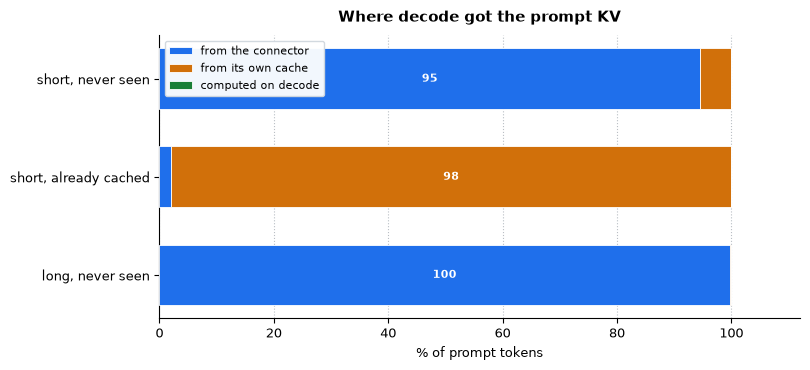

  how to read it: only the first crossed between pods — the other two are local to decode
  case                   prompt tokens  connector  own cache  computed
  ---------------------  -------------  ---------  ---------  --------
  short, never seen              1,473      94.6%       5.4%      0.0%
  short, already cached          1,470       2.0%      98.0%      0.0%
  long, never seen              26,377      99.8%       0.2%      0.0%
  PASS  decode recomputed under 10% of the prompt in every case

  >> On a prompt the engine has never seen, 97% of the KV crosses from prefill — that is disaggregation doing its job, and it is the only case where it does any. On a repeat the local cache serves it and the connector falls idle. So how much work the hop does is decided entirely by how novel the traffic is, which is a property of the workload rather than of the cluster.



Report(title='02-baseline', subtitle='', blocks=[_Block(kind='table', payload=(['stage of the speech path', 'budget', ''], [['ASR endpoint and finalize', '300 ms', ''], ['LLM TTFT', '800 ms', 'what the engine is held to'], ['TTS first chunk', '200 ms', ''], ['network and orchestration', '200 ms', ''], ['first audio', '1500 ms', 'what a listener tolerates']]), note='these are serial on the way to first audio, so the engine gets a slice of the 1.5s a listener tolerates, not all of it.'), _Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='With room to spare, what does each component actually do — and does that change with prompt length and cache state?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '0.8s'], ['inter-token latency p95', '0.08s'], ['preemptions', '0']]), note=''), _Block(kind='text', payload='Falsified by: the prefix cache hitting on text the engine has never seen, decode recomputing a prompt prefill alre

In [5]:
report.heading('3. Where each prompt\'s KV comes from')
labels = [results[k].case.label for k in results]
pct = lambda m, attr: (getattr(m, attr) / m.prompt_tokens * 100
                       if m.prompt_tokens else 0.0)

# Stacked: these are parts of one prompt and sum to 100%, so the segment IS
# the composition. Grouped bars would make the reader add them up by eye.
report.bar('Where decode got the prompt KV', labels, {
    'from the connector': [pct(results[k], 'from_connector') for k in results],
    'from its own cache': [pct(results[k], 'from_cache') for k in results],
    'computed on decode': [pct(results[k], 'computed') for k in results],
}, ylabel='% of prompt tokens', stacked=True, horizontal=True,
   note='only the first crossed between pods — the other two are local to decode')

report.table(['case', 'prompt tokens', 'connector', 'own cache', 'computed'],
             [[results[k].case.label, f'{results[k].prompt_tokens:,.0f}',
               f"{pct(results[k], 'from_connector'):.1f}%",
               f"{pct(results[k], 'from_cache'):.1f}%",
               f"{pct(results[k], 'computed'):.1f}%"] for k in results])

novel = [k for k in results if results[k].case.prefix == 'novel']
hop_novel = sum(pct(results[k], 'from_connector') for k in novel) / max(len(novel), 1)
report.verdict(all(pct(results[k], 'computed') < 10 for k in results),
               'decode recomputed under 10% of the prompt in every case')
report.conclusion(
    f'On a prompt the engine has never seen, {hop_novel:.0f}% of the KV crosses '
    'from prefill — that is disaggregation doing its job, and it is the only '
    'case where it does any. On a repeat the local cache serves it and the '
    'connector falls idle. So how much work the hop does is decided entirely by '
    'how novel the traffic is, which is a property of the workload rather than '
    'of the cluster.')


## 4. What the listener waits for

Prefill and decode run **in series**, so neither pool's own TTFT is what a
person experiences. The wait is prefill's whole request, then the hop, then
decode's first token.



4. What the listener waits for


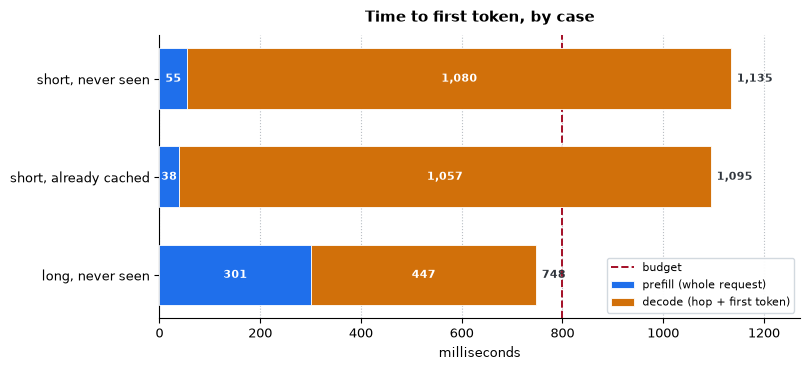

  how to read it: dashed line is the 800 ms the engine is allowed inside a listener's 1.5s
  case                   prefill  decode   user TTFT  vs budget
  ---------------------  -------  -------  ---------  ---------
  short, never seen      55 ms    1080 ms  1135 ms    1.4x     
  short, already cached  38 ms    1057 ms  1095 ms    1.4x     
  long, never seen       301 ms   447 ms   748 ms     0.9x     
  -- user TTFT is the first two added, because they happen one after the other.
  MISS  TTFT p95                     1.13536s <= 0.8s
        why it matters: A voice agent's latency is dead air, and the listener's 1.5s covers the whole path: ASR, the engine, then TTS. 0.8s is what remains for first token once 0.7s of the rest is paid for.

  >> The slowest case is "short, never seen" at 1135 ms, of which 95% is decode-side. That is 1.4x the 0.8s budget with the cluster idle and five requests in flight, so load is not what breaks it — the hop and decode startup do, before any queue e

In [6]:
report.heading('4. What the listener waits for')
# Stacked because the two run in series and add up to the wait. Totals are
# annotated so the budget comparison needs no arithmetic.
report.bar('Time to first token, by case', labels, {
    'prefill (whole request)': [results[k].prefill_e2e * 1000 for k in results],
    'decode (hop + first token)': [results[k].decode_ttft * 1000 for k in results],
}, ylabel='milliseconds', hline=TTFT_BUDGET_S * 1000,
   stacked=True, horizontal=True, total=True,
   note=f'dashed line is the {TTFT_BUDGET_S*1000:.0f} ms the engine is allowed '
        'inside a listener\'s 1.5s')

report.table(['case', 'prefill', 'decode', 'user TTFT', 'vs budget'],
             [[results[k].case.label,
               f'{results[k].prefill_e2e*1000:.0f} ms',
               f'{results[k].decode_ttft*1000:.0f} ms',
               f'{results[k].user_ttft*1000:.0f} ms',
               f'{results[k].user_ttft/TTFT_BUDGET_S:.1f}x'] for k in results],
             note='user TTFT is the first two added, because they happen one '
                  'after the other.')

worst = max(results, key=lambda k: results[k].user_ttft) if results else None
if worst:
    report.slo('ttft_p95', results[worst].user_ttft)
    w = results[worst]
    report.conclusion(
        f'The slowest case is "{w.case.label}" at {w.user_ttft*1000:.0f} ms, of '
        f'which {w.decode_ttft/max(w.user_ttft,1e-9):.0%} is decode-side. '
        + (f'That is {w.user_ttft/TTFT_BUDGET_S:.1f}x the {TTFT_BUDGET_S:g}s budget '
           'with the cluster idle and five requests in flight, so load is not what '
           'breaks it — the hop and decode startup do, before any queue exists.'
           if w.user_ttft > TTFT_BUDGET_S else
           f'That fits inside the {TTFT_BUDGET_S:g}s budget, so the engine has '
           'headroom for whatever load costs.'))


## 5. The prefix cache

The cache is the reason a repeat is cheap. It is also the reason a baseline
taken on repeated prompts flatters the whole system.



5. The prefix cache


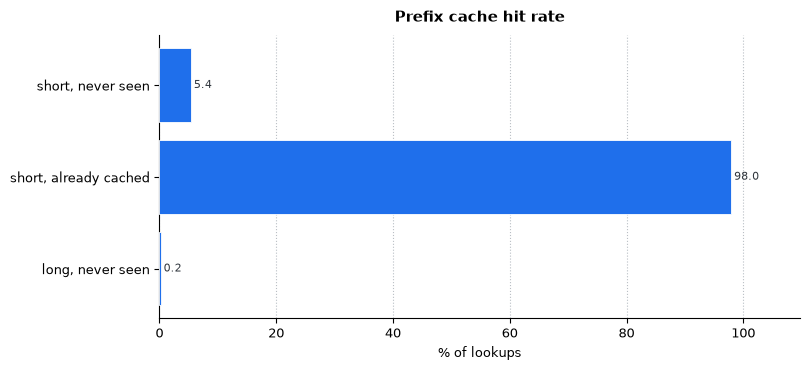

  how to read it: the mirror image of the connector chart above — where one is busy the other is idle
  prefix state  mean hit rate  what it means                        
  ------------  -------------  -------------------------------------
  novel                  2.8%  the engine has not seen this text    
  repeat                98.0%  identical to something already served
  PASS  the cache misses on new text and hits on repeats

  >> Novel prompts hit 2.8% and repeats 98.0%, so the cache is keyed on the prefix we control rather than reporting a hit for everything. 



Report(title='02-baseline', subtitle='', blocks=[_Block(kind='table', payload=(['stage of the speech path', 'budget', ''], [['ASR endpoint and finalize', '300 ms', ''], ['LLM TTFT', '800 ms', 'what the engine is held to'], ['TTS first chunk', '200 ms', ''], ['network and orchestration', '200 ms', ''], ['first audio', '1500 ms', 'what a listener tolerates']]), note='these are serial on the way to first audio, so the engine gets a slice of the 1.5s a listener tolerates, not all of it.'), _Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='With room to spare, what does each component actually do — and does that change with prompt length and cache state?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '0.8s'], ['inter-token latency p95', '0.08s'], ['preemptions', '0']]), note=''), _Block(kind='text', payload='Falsified by: the prefix cache hitting on text the engine has never seen, decode recomputing a prompt prefill alre

In [7]:
report.heading('5. The prefix cache')
report.bar('Prefix cache hit rate', labels,
           {'hit rate (%)': [results[k].cache_hit_rate * 100 for k in results]},
           ylabel='% of lookups', horizontal=True,
           note='the mirror image of the connector chart above — where one is '
                'busy the other is idle')

by_prefix = {}
for k, m in results.items():
    by_prefix.setdefault(m.case.prefix, []).append(m.cache_hit_rate)
avg = {p: sum(v) / len(v) for p, v in by_prefix.items()}
report.table(['prefix state', 'mean hit rate', 'what it means'],
             [[p, f'{avg[p]:.1%}',
               {'novel': 'the engine has not seen this text',
                'repeat': 'identical to something already served',
                'partial': 'shares half its tokens with a warmed prompt'}[p]]
              for p in avg])
report.verdict(avg.get('novel', 1.0) < 0.5 and avg.get('repeat', 0.0) > 0.9,
               'the cache misses on new text and hits on repeats')
report.conclusion(
    f"Novel prompts hit {avg.get('novel', 0):.1%} and repeats {avg.get('repeat', 0):.1%}, "
    'so the cache is keyed on the prefix we control rather than reporting a hit '
    'for everything. '
    + (f"Half-shared prompts hit {avg['partial']:.1%}, which is the number a real "
       'session sits nearest: a system prompt and sources that repeat, with a new '
       'question each turn.' if 'partial' in avg else ''))


## 6. The promises nothing else checks

Inter-token latency decides whether speech plays without gaps. A preemption
is a stall mid-sentence — the exact failure admission control exists to
prevent.


In [8]:
report.heading('6. Inter-token latency and preemptions')
itl = [results[k].itl for k in results if results[k].itl > 0]
itl_mean = sum(itl) / len(itl) if itl else 0.0
tok_s = 1 / itl_mean if itl_mean else 0.0
pre = sum(results[k].after.get('preemptions', 0) - results[k].before.get('preemptions', 0)
          for k in results)

report.table(['', 'measured', 'budget', ''], [
    ['inter-token latency', f'{itl_mean*1000:.1f} ms',
     f"{SLOS['itl_p95'].target*1000:.0f} ms", f'{tok_s:,.0f} tokens/s generated'],
    ['speech consumes', f'{SPEECH_TOKENS_PER_S:g} tokens/s', '-',
     f'TTS runs dry past {ITL_STUTTER_S*1000:.0f} ms per token'],
    ['preemptions', f'{pre:,.0f}', '0', 'a stall mid-sentence'],
])
report.slo('itl_p95', itl_mean)
report.slo('preemptions', pre)
report.conclusion(
    f'The engine produces {tok_s:,.0f} tokens/s against speech spoken at '
    f'{SPEECH_TOKENS_PER_S:g} — about {tok_s/SPEECH_TOKENS_PER_S:.0f}x faster, so once '
    'audio starts it plays continuously. '
    + ('Nothing was preempted.' if pre == 0 else
       f'{pre:,.0f} preemptions occurred, each an audible stall.'))



6. Inter-token latency and preemptions
                       measured      budget                                    
  -------------------  ------------  ------  ----------------------------------
  inter-token latency  5.6 ms        80 ms   180 tokens/s generated            
  speech consumes      3.3 tokens/s  -       TTS runs dry past 303 ms per token
  preemptions          0             0       a stall mid-sentence              
  MET   inter-token latency p95      0.00556977s <= 0.08s
  MET   preemptions                  0 <= 0

  >> The engine produces 180 tokens/s against speech spoken at 3.3 — about 54x faster, so once audio starts it plays continuously. Nothing was preempted.



Report(title='02-baseline', subtitle='', blocks=[_Block(kind='table', payload=(['stage of the speech path', 'budget', ''], [['ASR endpoint and finalize', '300 ms', ''], ['LLM TTFT', '800 ms', 'what the engine is held to'], ['TTS first chunk', '200 ms', ''], ['network and orchestration', '200 ms', ''], ['first audio', '1500 ms', 'what a listener tolerates']]), note='these are serial on the way to first audio, so the engine gets a slice of the 1.5s a listener tolerates, not all of it.'), _Block(kind='heading', payload='Objective', note=''), _Block(kind='text', payload='With room to spare, what does each component actually do — and does that change with prompt length and cache state?', note=''), _Block(kind='table', payload=(['SLO under test', 'target'], [['TTFT p95', '0.8s'], ['inter-token latency p95', '0.08s'], ['preemptions', '0']]), note=''), _Block(kind='text', payload='Falsified by: the prefix cache hitting on text the engine has never seen, decode recomputing a prompt prefill alre

## Verdict


In [9]:
print()
fails = report.failures()
if fails:
    print('NOT SAFE TO PROCEED — fix these first:')
    for f in fails:
        print(f'  - {f}')
else:
    print('Every component behaves as expected with room to spare. Next: 03-capacity')
if broken:
    print()
    print('Cases that could not run:')
    for k, why in broken.items():
        print(f'  - {CASES[k].label}: {why}')



NOT SAFE TO PROCEED — fix these first:
  - all 5 cases ran (2 did not)
  - SLO MISSED — TTFT p95: 1.13536s <= 0.8s

Cases that could not run:
  - long, already cached: long_repeat: the warm-up request failed (503 server_is_overloaded), so the cache state this case depends on was never established
  - long, half shared: long_partial: the warm-up request failed (503 server_is_overloaded), so the cache state this case depends on was never established
